In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt3
import os
import glob

# Files Loading

In [2]:
import pandas as pd
import glob, os

stocks = {}
for path in glob.glob("stocks/*.csv"):          # change "stocks" to your folder path
    name = os.path.splitext(os.path.basename(path))[0]
    stocks[name] = pd.read_csv(path)

print(len(stocks), "files loaded")

218 files loaded


In [3]:
print(stocks.keys())

dict_keys(['360ONE.NS', '3MINDIA.NS', 'ABB.NS', 'ABCAPITAL.NS', 'ADANIENT.NS', 'ADANIGREEN.NS', 'ADANIPORTS.NS', 'ADANIPOWER.NS', 'ALKEM.NS', 'AMBUJACEM.NS', 'APARINDS.NS', 'APLAPOLLO.NS', 'APOLLOHOSP.NS', 'ASHOKLEY.NS', 'ASIANPAINT.NS', 'ASTRAL.NS', 'ATGL.NS', 'AUBANK.NS', 'AUROPHARMA.NS', 'AXISBANK.NS', 'BAJAJ-AUTO.NS', 'BAJAJFINSV.NS', 'BAJAJHLDNG.NS', 'BAJFINANCE.NS', 'BALKRISIND.NS', 'BANKBARODA.NS', 'BANKINDIA.NS', 'BDL.NS', 'BEL.NS', 'BERGEPAINT.NS', 'BHARATFORG.NS', 'BHARTIARTL.NS', 'BHEL.NS', 'BIOCON.NS', 'BLUESTARCO.NS', 'BOSCHLTD.NS', 'BPCL.NS', 'BRITANNIA.NS', 'BSE.NS', 'CANBK.NS', 'CGPOWER.NS', 'CHOLAFIN.NS', 'CHOLAHLDNG.NS', 'CIPLA.NS', 'COALINDIA.NS', 'COCHINSHIP.NS', 'COFORGE.NS', 'COLPAL.NS', 'CONCOR.NS', 'COROMANDEL.NS', 'CRISIL.NS', 'CUMMINSIND.NS', 'DABUR.NS', 'DALBHARAT.NS', 'DIVISLAB.NS', 'DIXON.NS', 'DLF.NS', 'DMART.NS', 'DRREDDY.NS', 'EICHERMOT.NS', 'ENDURANCE.NS', 'ESCORTS.NS', 'FACT.NS', 'FEDERALBNK.NS', 'FLUOROCHEM.NS', 'FORTIS.NS', 'GAIL.NS', 'GET_AND_D.NS',

In [4]:
stocks["ZOMATO.NS"] 

,Date,Open,High,Low,Close,Volume
0,2021-07-23 00:00:00+05:30,116.000000,138.899994,115.000000,126.000000,694895290
1,2021-07-26 00:00:00+05:30,126.349998,143.750000,125.300003,140.649994,249723854
2,2021-07-27 00:00:00+05:30,141.699997,147.800003,127.750000,132.899994,240341900
3,2021-07-28 00:00:00+05:30,131.000000,135.000000,123.550003,131.199997,159793731
4,2021-07-29 00:00:00+05:30,134.949997,144.000000,132.199997,141.550003,117973089
...,...,...,...,...,...,...
560,2023-10-26 00:00:00+05:30,107.500000,108.000000,101.250000,106.449997,108605538
561,2023-10-27 00:00:00+05:30,107.349998,109.250000,105.050003,105.650002,43738547
562,2023-10-30 00:00:00+05:30,106.199997,108.599998,105.699997,107.699997,48282252
563,2023-10-31 00:00:00+05:30,107.849998,108.150002,104.250000,105.099998,49382539


# Converting Date -> Index

In [5]:
for name in list(stocks.keys()):
    df = stocks[name]
    df.columns = df.columns.str.strip()

    # Take only the YYYY-MM-DD part, which avoids timezone problems entirely
    df["Date"] = pd.to_datetime(df["Date"].astype(str).str[:10], format="%Y-%m-%d", errors="coerce")

    df = df.dropna(subset=["Date"]).set_index("Date").sort_index()
    df = df[~df.index.duplicated(keep="last")]
    stocks[name] = df

In [6]:
stocks["ZOMATO.NS"] 

,Open,High,Low,Close,Volume
Date,,,,,
2021-07-23,116.000000,138.899994,115.000000,126.000000,694895290
2021-07-26,126.349998,143.750000,125.300003,140.649994,249723854
2021-07-27,141.699997,147.800003,127.750000,132.899994,240341900
2021-07-28,131.000000,135.000000,123.550003,131.199997,159793731
2021-07-29,134.949997,144.000000,132.199997,141.550003,117973089
...,...,...,...,...,...
2023-10-26,107.500000,108.000000,101.250000,106.449997,108605538
2023-10-27,107.349998,109.250000,105.050003,105.650002,43738547
2023-10-30,106.199997,108.599998,105.699997,107.699997,48282252


# Missing Values

In [7]:
for name, df in stocks.items():
    missing = df.isna().sum()
    if missing.any():
        print(f"{name}:\n{missing[missing > 0]}\n")

# Duplicate Values

In [8]:
for name, df in stocks.items():
    n = df.index.duplicated().sum()
    if n:
        print(name, "duplicate dates:", n)

In [9]:
for name, df in stocks.items():
    n = df.reset_index().duplicated().sum()
    if n:
        print(name, "fully duplicated rows:", n)

In [10]:
df = stocks["RELIANCE.NS"]            # pick any ticker
print(df[df.index.duplicated(keep=False)])

Empty DataFrame
Columns: [Open, High, Low, Close, Volume]
Index: []


# Providing each Stock with RSI and MA


In [11]:
import pandas as pd

def rsi(close, n=14):
    """Wilder's RSI."""
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    # Wilder's smoothing = EMA with alpha = 1/n
    avg_gain = gain.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/n, min_periods=n, adjust=False).mean()

    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

In [12]:

def period_rsi(close, freq, n=14):
    """RSI on weekly/monthly closes, mapped back to daily rows."""
    # group by calendar period and take the last trading day of each
    if freq == "W":
        key = close.index.to_period("W-FRI")
    else:
        key = close.index.to_period("M")
    period_close = close.groupby(key).last()          # last close of each period
    last_dates = close.index.to_series().groupby(key).last()
    period_close.index = last_dates.values            # label by actual last trading day
    r = rsi(period_close, n)
    return r.reindex(close.index, method="ffill")

for name, df in stocks.items():
    close = df["Close"]

    df["RSI_Daily"]   = rsi(close)
    df["RSI_Weekly"]  = period_rsi(close, "W")
    df["RSI_Monthly"] = period_rsi(close, "M")

    df["MA20"]  = close.rolling(20).mean()
    df["MA40"]  = close.rolling(40).mean()
    df["MA200"] = close.rolling(200).mean()

    stocks[name] = df

In [13]:
stocks["ZOMATO.NS"] 

,Open,High,Low,Close,Volume,RSI_Daily,RSI_Weekly,RSI_Monthly,MA20,MA40,MA200
Date,,,,,,,,,,,
2021-07-23,116.000000,138.899994,115.000000,126.000000,694895290,NaN,NaN,NaN,NaN,NaN,NaN
2021-07-26,126.349998,143.750000,125.300003,140.649994,249723854,NaN,NaN,NaN,NaN,NaN,NaN
2021-07-27,141.699997,147.800003,127.750000,132.899994,240341900,NaN,NaN,NaN,NaN,NaN,NaN
2021-07-28,131.000000,135.000000,123.550003,131.199997,159793731,NaN,NaN,NaN,NaN,NaN,NaN
2021-07-29,134.949997,144.000000,132.199997,141.550003,117973089,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2023-10-26,107.500000,108.000000,101.250000,106.449997,108605538,51.251429,77.779479,60.089211,107.2200,103.19375,72.98175
2023-10-27,107.349998,109.250000,105.050003,105.650002,43738547,49.520381,66.584898,60.089211,107.4975,103.46750,73.22825
2023-10-30,106.199997,108.599998,105.699997,107.699997,48282252,53.824322,66.584898,60.089211,107.8850,103.66500,73.48575


# Classifying each Stock into Sector Group

In [14]:
sector_symbols = {
    "Banks": ["AXISBANK","HDFCBANK","ICICIBANK","KOTAKBANK","INDUSINDBK","FEDERALBNK","IDFCFIRSTB",
              "YESBANK","AUBANK","IDBI","BANKBARODA","BANKINDIA","CANBK","INDIANB","IOB","MAHABANK",
              "PNB","SBIN","UCOBANK","UNIONBANK"],
    "Financial Services": ["360ONE","ABCAPITAL","BAJAJFINSV","BAJAJHLDNG","BAJFINANCE","BSE","CHOLAFIN",
              "CHOLAHLDNG","CRISIL","GICRE","HDFCAMC","HDFCLIFE","HUDCO","ICICIGI","ICICIPRULI","IRFC",
              "L_AND_TFH","LICI","M_AND_MFIN","MFSL","MOTILALOFS","MUTHOOTFIN","NAM-INDIA","PFC",
              "POLICYBZR","POONAWALLA","RECLTD","SBICARD","SBILIFE","SHRIRAMFIN","SUNDARMFIN","TATAINVEST","PAYTM"],
    "IT": ["COFORGE","HCLTECH","INFY","LTIM","LTTS","MPHASIS","OFSS","PERSISTENT","TCS","TECHM","WIPRO"],
    "Automobiles": ["ASHOKLEY","BAJAJ-AUTO","EICHERMOT","HEROMOTOCO","M_AND_M","MARUTI","TATAMOTORS","TVSMOTOR","ESCORTS"],
    "Auto Components": ["BALKRISIND","BHARATFORG","BOSCHLTD","ENDURANCE","MOTHERSON","MRF","SCHAEFFLER","TIINDIA","UNOMINDA"],
    "Pharma & Healthcare": ["ALKEM","APOLLOHOSP","AUROPHARMA","BIOCON","CIPLA","DIVISLAB","DRREDDY","FORTIS","GLAXO",
              "GLENMARK","IPCALAB","LAURUSLABS","LUPIN","MAXHEALTH","MEDANTA","NH","SUNPHARMA","TORNTPHARM","ZYDUSLIFE"],
    "FMCG": ["BRITANNIA","COLPAL","DABUR","GODREJCP","HINDUNILVR","ITC","MARICO","PATANJALI","PGHH","RADICO",
             "TATACONSUM","UBL","VBL","MCDOWELL-N","GODFRYPHLP"],
    "Oil & Gas": ["BPCL","GAIL","HINDPETRO","IOC","OIL","ONGC","PETRONET","RELIANCE","ATGL"],
    "Power": ["ADANIGREEN","ADANIPOWER","JSWENERGY","NHPC","NTPC","POWERGRID","SJVN","TATAPOWER","TORNTPOWER"],
    "Metals & Mining": ["COALINDIA","HINDALCO","HINDZINC","JINDALSTEL","JSL","JSWSTEEL","NATIONALUM","NMDC",
                        "SAIL","TATASTEEL","VEDL","APLAPOLLO"],
    "Cement": ["AMBUJACEM","DALBHARAT","GRASIM","JKCEMENT","SHREECEM","ULTRACEMCO"],
    "Capital Goods": ["3MINDIA","ABB","APARINDS","BDL","BEL","BHEL","CGPOWER","COCHINSHIP","CUMMINSIND","GET_AND_D",
                      "HAL","KAYNES","KEI","LT","MAZDOCK","POLYCAB","POWERINDIA","RVNL","SIEMENS","SOLARINDS",
                      "SUZLON","THERMAX"],
    "Consumer Durables": ["BLUESTARCO","DIXON","HAVELLS","VOLTAS","TITAN"],
    "Chemicals & Paints": ["ASIANPAINT","BERGEPAINT","PIDILITIND","PIIND","SRF","UPL","FLUOROCHEM","COROMANDEL",
                           "FACT","GODREJIND","LINDEINDIA","ASTRAL","SUPREMEIND"],
    "Realty": ["DLF","GODREJPROP","LODHA","OBEROIRLTY","PHOENIXLTD","PRESTIGE"],
    "Infra & Logistics": ["ADANIENT","ADANIPORTS","CONCOR","GMRINFRA","INDIGO","IRCTC"],
    "Telecom": ["BHARTIARTL","IDEA","INDUSTOWER","TATACOMM"],
    "Retail & Consumer Services": ["DMART","JUBLFOOD","KALYANKJIL","NYKAA","TRENT","ZOMATO","NAUKRI","INDHOTEL"],
    "Textiles & Apparel": ["KPRMILL","PAGEIND"],
}

# ticker -> sector lookup (adds the .NS suffix to match your dict keys)
stock_to_sector = {f"{sym}.NS": sec for sec, syms in sector_symbols.items() for sym in syms}

# sector -> {ticker: DataFrame}
sector_groups = {}
for name, df in stocks.items():
    sec = stock_to_sector.get(name)
    if sec:
        sector_groups.setdefault(sec, {})[name] = df

# Sanity checks
unmapped = [n for n in stocks if n not in stock_to_sector]
missing_files = [t for t in stock_to_sector if t not in stocks]
print("Stocks with no sector:", unmapped)
print("Mapped but no file:", missing_files)

for sec, members in sector_groups.items():
    print(f"{sec}: {len(members)}")

Stocks with no sector: []
Mapped but no file: []
Financial Services: 33
Capital Goods: 22
Infra & Logistics: 6
Power: 9
Pharma & Healthcare: 19
Cement: 6
Metals & Mining: 12
Automobiles: 9
Chemicals & Paints: 13
Oil & Gas: 9
Banks: 20
Auto Components: 9
Telecom: 4
Consumer Durables: 5
FMCG: 15
IT: 11
Realty: 6
Retail & Consumer Services: 8
Textiles & Apparel: 2


# Sector Data Loading & Performing Basic Operations

## Load Nifty + Sector Data


In [15]:
import pandas as pd
import glob, os

sector_data = {}

for path in sorted(glob.glob("indices/*.csv")):
    name = os.path.splitext(os.path.basename(path))[0]
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    s = df["Date"].astype(str).str.strip().str[:10].str.replace("/", "-", regex=False)
    fmt = "%Y-%m-%d" if s.str.match(r"^\d{4}-").all() else "%d-%m-%Y"
    df["Date"] = pd.to_datetime(s, format=fmt)

    df = df.set_index("Date").sort_index()
    df = df[~df.index.duplicated(keep="last")]
    sector_data[name] = df

In [16]:
for name, df in sector_data.items():
    drop_cols = [c for c in df.columns if c.startswith("Unnamed") or c.lower() in ("index", "level_0")]
    sector_data[name] = df.drop(columns=drop_cols)

In [17]:
sector_data["Automobiles"].head()

,Open,High,Low,Close,Volume
Date,,,,,
2011-07-13,3774.28,3774.28,3774.28,3774.28,0.0
2011-07-14,3783.65,3783.65,3783.65,3783.65,0.0
2011-07-15,3783.65,3783.65,3783.65,3783.65,0.0
2011-07-18,3759.19,3759.19,3759.19,3759.19,0.0
2011-07-19,3720.54,3720.54,3720.54,3720.54,0.0


# Providing each Sector with RSI and MA


In [18]:
import pandas as pd

def rsi(close, n=14):
    """Wilder's RSI"""
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
    rs = avg_gain / avg_loss
    return 100 - 100 / (1 + rs)

def period_rsi(close, freq, n=14):
    """RSI on weekly/monthly closes, mapped back to daily rows (no look-ahead)."""
    key = close.index.to_period("W-FRI") if freq == "W" else close.index.to_period("M")
    period_close = close.groupby(key).last()
    period_close.index = close.index.to_series().groupby(key).last().values
    return rsi(period_close, n).reindex(close.index, method="ffill")

for name, df in sector_data.items():
    close = pd.to_numeric(df["Close"], errors="coerce")

    df["RSI_Daily"]   = rsi(close)
    df["RSI_Weekly"]  = period_rsi(close, "W")
    df["RSI_Monthly"] = period_rsi(close, "M")

    df["MA20"]  = close.rolling(20).mean()
    df["MA40"]  = close.rolling(40).mean()
    df["MA200"] = close.rolling(200).mean()

    sector_data[name] = df

In [19]:
sector_data["Automobiles"].head()

,Open,High,Low,Close,Volume,RSI_Daily,RSI_Weekly,RSI_Monthly,MA20,MA40,MA200
Date,,,,,,,,,,,
2011-07-13,3774.28,3774.28,3774.28,3774.28,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-14,3783.65,3783.65,3783.65,3783.65,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-15,3783.65,3783.65,3783.65,3783.65,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-18,3759.19,3759.19,3759.19,3759.19,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-19,3720.54,3720.54,3720.54,3720.54,0.0,NaN,NaN,NaN,NaN,NaN,NaN


# Sectors and Stocks Together


In [20]:
sector_plan = {
    # sector name:           (key in sector_data,      stock groups from sector_symbols)
    "Automobiles":           ("Automobiles",           ["Automobiles", "Auto Components"]),
    "Banks & Fin Services":  ("Banks",                 ["Banks", "Financial Services"]),
    "FMCG":                  ("FMCG",                  ["FMCG"]),
    "IT":                    ("IT",                    ["IT"]),
    "Metals & Mining":       ("Metals_and_Mining",     ["Metals & Mining"]),
    "Oil & Gas":             ("Oil_and_Gas",           ["Oil & Gas"]),
    "Power":                 ("Power",                 ["Power"]),
    "Pharma & Healthcare":   ("Pharma_and_Healthcare", ["Pharma & Healthcare"]),
    "Realty":                ("Realty",                ["Realty"]),
}

sector_bundle = {}
for sector, (idx_key, groups) in sector_plan.items():
    tickers = [f"{sym}.NS" for g in groups for sym in sector_symbols[g]]
    sector_bundle[sector] = {
        "index":  sector_data[idx_key],
        "stocks": {t: stocks[t] for t in tickers if t in stocks},
    }

nifty = sector_data["NIFTY50"]

# stocks in sectors with no index, kept aside
used = {t for b in sector_bundle.values() for t in b["stocks"]}
other_stocks = {t: d for t, d in stocks.items() if t not in used}

In [21]:
for sector, b in sector_bundle.items():
    print(f"{sector:25s} index rows: {len(b['index']):5d}   stocks: {len(b['stocks'])}")
print("\nStocks without a sector index:", len(other_stocks))

Automobiles               index rows:  2611   stocks: 18
Banks & Fin Services      index rows:  4125   stocks: 53
FMCG                      index rows:  2723   stocks: 15
IT                        index rows:  4576   stocks: 11
Metals & Mining           index rows:  2611   stocks: 12
Oil & Gas                 index rows:  2723   stocks: 9
Power                     index rows:  2723   stocks: 9
Pharma & Healthcare       index rows:  2723   stocks: 19
Realty                    index rows:  2859   stocks: 6

Stocks without a sector index: 66


# Time Line when each Sector was above RSI 60


=== Automobiles ===
     Start        End  Months  Ongoing
2014-02-28 2015-07-31      18    False
2015-11-30 2015-12-31       2    False
2016-05-31 2016-10-30       6    False
2017-01-31 2018-02-28      14    False
2018-04-30 2018-04-30       1    False
2021-01-29 2021-03-31       3    False
2021-05-31 2021-06-30       2    False
2021-09-30 2021-10-29       2    False
2021-12-31 2022-01-31       2     True

=== Banks ===
     Start        End  Months  Ongoing
2006-08-31 2008-02-29      19    False
2008-04-30 2008-04-30       1    False
2009-09-30 2010-12-31      16    False
2014-12-31 2014-12-31       1    False

=== FMCG ===
     Start        End  Months  Ongoing
2012-04-30 2015-08-31      41    False
2015-10-30 2015-12-31       3    False
2016-06-30 2016-10-30       5    False
2017-01-31 2018-09-28      21    False
2018-11-30 2019-01-31       3    False
2019-03-29 2019-04-30       2    False
2019-09-30 2019-10-31       2    False
2020-12-31 2021-01-29       2    False
2021-03-31 202

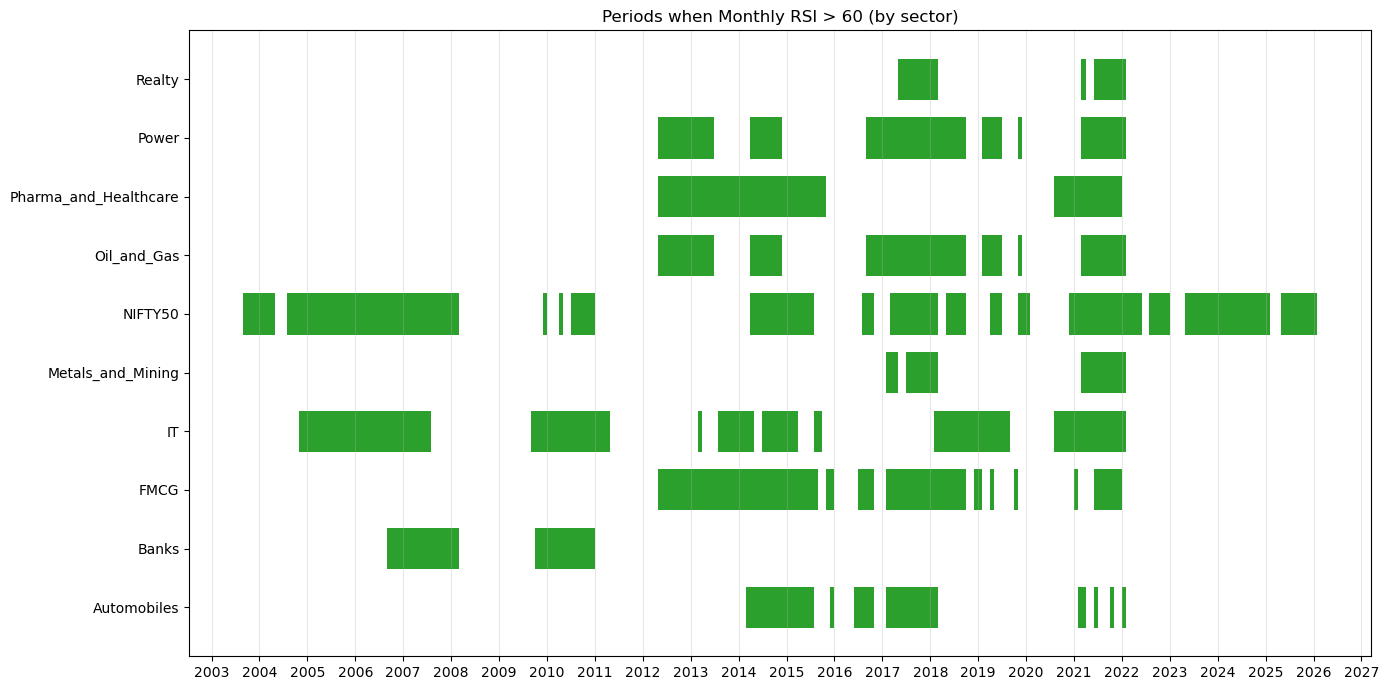

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

THRESHOLD = 60
RSI_LEN = 14

def rsi(close, n=14):
    """Wilder's RSI."""
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/n, min_periods=n, adjust=False).mean()
    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

def get_close(df):
    """Find the close column even if it's named slightly differently."""
    for c in df.columns:
        if c.lower() == "close":
            col = c
            break
    else:
        cands = [c for c in df.columns if "close" in c.lower()]
        if not cands:
            raise KeyError(f"No close column in {list(df.columns)}")
        col = cands[0]
    return pd.to_numeric(df[col].astype(str).str.replace(",", ""), errors="coerce")

def monthly_rsi(df, n=RSI_LEN):
    close = get_close(df).dropna()
    key = close.index.to_period("M")
    m_close = close.groupby(key).last()                       # last close of each month
    m_close.index = close.index.to_series().groupby(key).last().values  # label by last trading day
    return rsi(m_close, n)

def rsi_spans(r, threshold=THRESHOLD):
    """Continuous runs where monthly RSI > threshold."""
    r = r.dropna()
    above = r > threshold
    run_id = (above != above.shift()).cumsum()
    spans = []
    for _, grp in above.groupby(run_id):
        if grp.iloc[0]:
            start, end = grp.index[0], grp.index[-1]
            spans.append({
                "Start": start,
                "End": end,
                "Months": len(grp),
                "Ongoing": end == r.index[-1],
            })
    return pd.DataFrame(spans)

# ---- compute for every sector ----
sector_rsi = {name: monthly_rsi(df) for name, df in sector_data.items()}

all_spans = []
for name, r in sector_rsi.items():
    sp = rsi_spans(r)
    if not sp.empty:
        sp.insert(0, "Sector", name)
        all_spans.append(sp)

timeline = pd.concat(all_spans, ignore_index=True)

# ---- print per sector ----
for name, grp in timeline.groupby("Sector"):
    print(f"\n=== {name} ===")
    print(grp[["Start", "End", "Months", "Ongoing"]].to_string(
        index=False,
        formatters={"Start": lambda d: d.strftime("%Y-%m-%d"),
                    "End":   lambda d: d.strftime("%Y-%m-%d")}))

# ---- latest monthly RSI per sector ----
latest = pd.Series({n: r.dropna().iloc[-1] for n, r in sector_rsi.items()})
print("\nLatest monthly RSI:")
print(latest.sort_values(ascending=False).round(1))

# ---- Gantt-style chart ----
sectors = list(sector_data.keys())
fig, ax = plt.subplots(figsize=(14, 0.5 * len(sectors) + 2))
for i, name in enumerate(sectors):
    grp = timeline[timeline["Sector"] == name]
    bars = [(mdates.date2num(r.Start), mdates.date2num(r.End) - mdates.date2num(r.Start))
            for r in grp.itertuples()]
    ax.broken_barh(bars, (i - 0.35, 0.7), facecolors="tab:green")

ax.set_yticks(range(len(sectors)))
ax.set_yticklabels(sectors)
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="x", alpha=0.3)
ax.set_title(f"Periods when Monthly RSI > {THRESHOLD} (by sector)")
plt.tight_layout()
plt.show()

# timeline.to_csv("sector_rsi_above_60_timeline.csv", index=False)
       

# Timeline when Stock Weekly and Monthly>60 


=== 360ONE.NS ===
     Start        End  Trading_Days  Calendar_Days  Ongoing
2021-02-05 2021-04-15            46             69    False
2021-07-16 2021-11-17            84            124    False
2022-01-14 2022-01-27             9             13    False
2022-02-04 2022-02-10             5              6    False
2022-04-01 2022-04-28            18             27    False
2022-09-09 2022-10-20            29             41    False
2022-10-28 2022-11-10             9             13    False
2022-12-16 2022-12-22             5              6    False
2023-01-20 2023-01-25             4              5    False
2023-02-03 2023-02-09             5              6    False
2023-06-30 2023-08-31            44             62    False
2023-09-08 2023-09-28            14             20    False
2023-10-13 2023-11-01            13             19     True

=== 3MINDIA.NS ===
     Start        End  Trading_Days  Calendar_Days  Ongoing
2003-09-30 2004-01-15            78            107    False
2


=== MARUTI.NS ===
     Start        End  Trading_Days  Calendar_Days  Ongoing
2004-12-03 2005-01-06            25             34    False
2005-02-11 2005-02-17             5              6    False
2005-08-05 2005-08-11             5              6    False
2005-09-02 2005-10-13            28             41    False
2005-10-21 2005-10-27             5              6    False
2005-11-11 2006-05-18           126            188    False
2006-09-01 2006-11-09            47             69    False
2007-09-21 2007-11-01            29             41    False
2009-05-29 2009-10-29           106            153    False
2009-11-06 2010-01-07            42             62    False
2010-10-29 2010-11-11             9             13    False
2012-11-30 2013-02-14            54             76    False
2013-04-30 2013-05-30            22             30    False
2013-12-31 2014-01-30            23             30    False
2014-03-31 2015-04-23           258            388    False
2015-04-30 2015-05-07


Summary:
               Episodes  Total_Days  Longest_Run  Valid_Days  \
Stock                                                          
TIINDIA.NS           17         644          156        1174   
ATGL.NS              11         509          166         931   
POLYCAB.NS           10         446          203         832   
MAZDOCK.NS            4         240          114         455   
POWERINDIA.NS        11         312           59         603   
...                 ...         ...          ...         ...   
ZOMATO.NS             1          22           22         269   
SUZLON.NS             9         283          106        4153   
GICRE.NS              1          64           64        1197   
SBICARD.NS            2          24           14         603   
HDFCAMC.NS            1          22           22         995   

               Pct_Time_Both_Above_60 Last_Data_Date  Currently_Both_Above_60  
Stock                                                                        

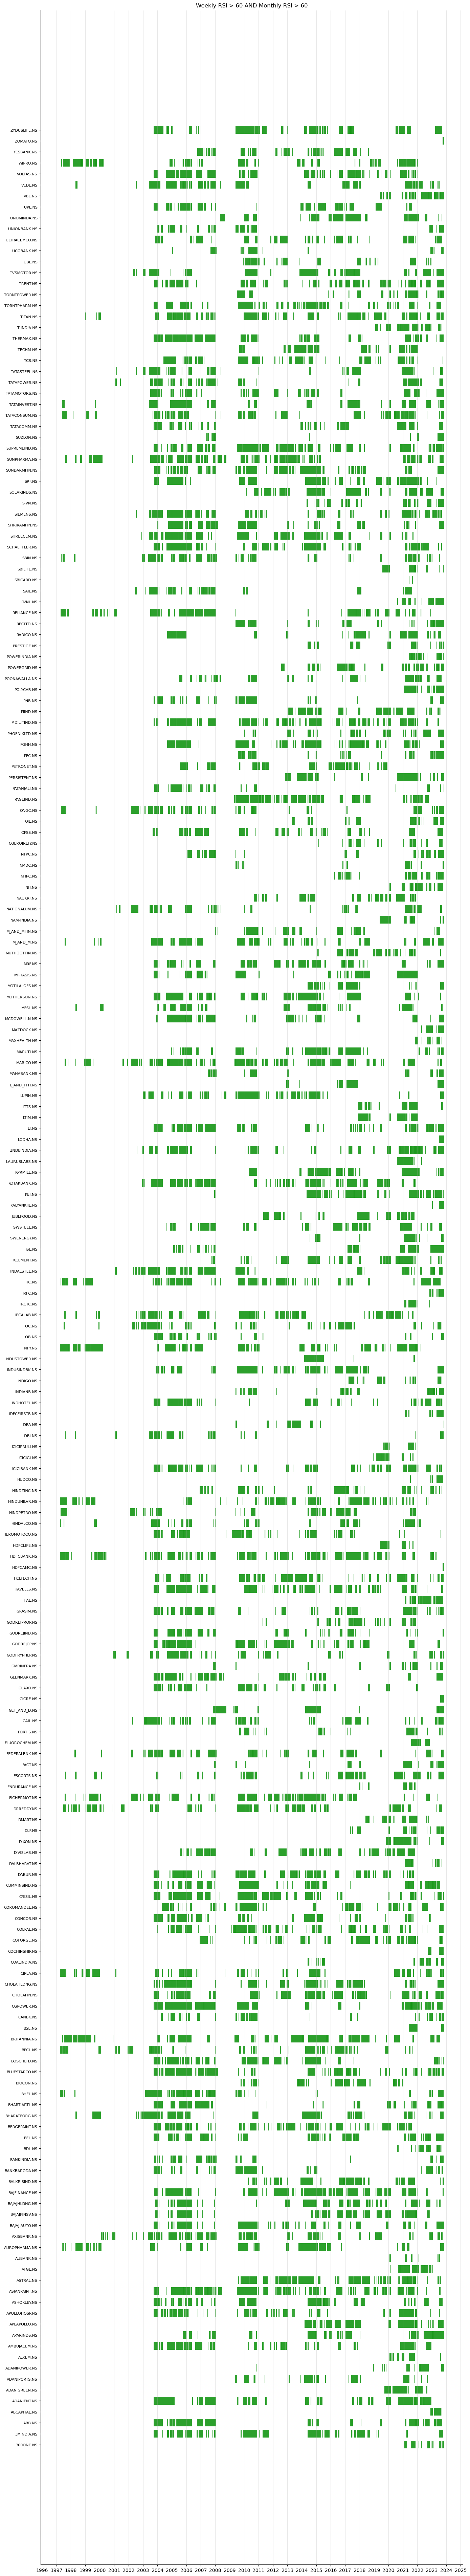

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

THRESHOLD = 60
MIN_DAYS = 1   # raise to e.g. 5 to ignore very short overlaps

def dual_rsi_spans(df, threshold=THRESHOLD):
    """Runs where weekly AND monthly RSI are both above threshold."""
    d = df[["RSI_Weekly", "RSI_Monthly"]].dropna()
    if d.empty:
        return pd.DataFrame()

    both = (d["RSI_Weekly"] > threshold) & (d["RSI_Monthly"] > threshold)
    run_id = (both != both.shift()).cumsum()

    spans = []
    for _, grp in both.groupby(run_id):
        if grp.iloc[0]:
            start, end = grp.index[0], grp.index[-1]
            spans.append({
                "Start": start,
                "End": end,
                "Trading_Days": len(grp),
                "Calendar_Days": (end - start).days,
                "Ongoing": end == d.index[-1],
            })
    return pd.DataFrame(spans)

# ---- build timeline for every stock ----
all_spans = []
for name, df in stocks.items():
    sp = dual_rsi_spans(df)
    if not sp.empty:
        sp = sp[sp["Trading_Days"] >= MIN_DAYS]
        sp.insert(0, "Stock", name)
        all_spans.append(sp)

timeline_stocks = pd.concat(all_spans, ignore_index=True)

# ---- print per stock ----
for name, grp in timeline_stocks.groupby("Stock"):
    print(f"\n=== {name} ===")
    print(grp[["Start", "End", "Trading_Days", "Calendar_Days", "Ongoing"]].to_string(
        index=False,
        formatters={"Start": lambda d: d.strftime("%Y-%m-%d"),
                    "End":   lambda d: d.strftime("%Y-%m-%d")}))

# ---- summary table ----
summary = timeline_stocks.groupby("Stock").agg(
    Episodes=("Start", "count"),
    Total_Days=("Trading_Days", "sum"),
    Longest_Run=("Trading_Days", "max"),
)
valid = pd.Series({
    n: df[["RSI_Weekly", "RSI_Monthly"]].dropna().shape[0] for n, df in stocks.items()
})
summary["Valid_Days"] = valid
summary["Pct_Time_Both_Above_60"] = (100 * summary["Total_Days"] / summary["Valid_Days"]).round(1)
summary["Last_Data_Date"] = pd.Series({
    n: df.index[-1].date() for n, df in stocks.items()
})
summary["Currently_Both_Above_60"] = pd.Series({
    n: (
        bool(
            df[["RSI_Weekly", "RSI_Monthly"]]
            .dropna()
            .iloc[-1]
            .gt(THRESHOLD)
            .all()
        )
        if not df[["RSI_Weekly", "RSI_Monthly"]].dropna().empty
        else False
    )
    for n, df in stocks.items()
})
print("\nSummary:")
print(summary.sort_values("Pct_Time_Both_Above_60", ascending=False))

# ---- Gantt chart (only stocks that had at least one span) ----
names = list(summary.index)
fig, ax = plt.subplots(figsize=(14, 0.35 * len(names) + 2))
for i, name in enumerate(names):
    grp = timeline_stocks[timeline_stocks["Stock"] == name]
    bars = [(mdates.date2num(r.Start), mdates.date2num(r.End) - mdates.date2num(r.Start) + 1)
            for r in grp.itertuples()]
    ax.broken_barh(bars, (i - 0.35, 0.7), facecolors="tab:green")

ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=8)
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="x", alpha=0.3)
ax.set_title(f"Weekly RSI > {THRESHOLD} AND Monthly RSI > {THRESHOLD}")
plt.tight_layout()
plt.show()

# timeline_stocks.to_csv("stocks_weekly_monthly_rsi_above_60.csv", index=False)

# Backtesting Analysis

Prepared 218 stocks (152 with sector index, 66 'other')

================ RESULTS ================
        Trades: 1069
       Signals: 6227
 Trades_per_yr: 52.8
       WinRate: 47.5
          AvgR: 0.3
            PF: 2.43
    Return_pct: 5350.8
      CAGR_pct: 21.8
     MaxDD_pct: -47.8
      Avg_open: 10.75
     AvgHold_d: 74.3
       Avg win: 17,882 | Avg loss: -6,655

Exit reasons:
 Stop         944
Stop(gap)    112
OpenAtEnd     13

By sector:
                       Trades  WinRate        PnL
Sector                                          
Other                    581     49.2  2811924.8
IT                        89     49.4   768464.2
Oil & Gas                 29     48.3   666504.7
Automobiles               59     47.5   460251.3
Metals & Mining           29     62.1   258122.2
FMCG                      67     40.3   203602.1
Power                     14     42.9    84437.1
Realty                    13     38.5    37116.3
Banks & Fin Services     117     41.9    31221.2
Pharma

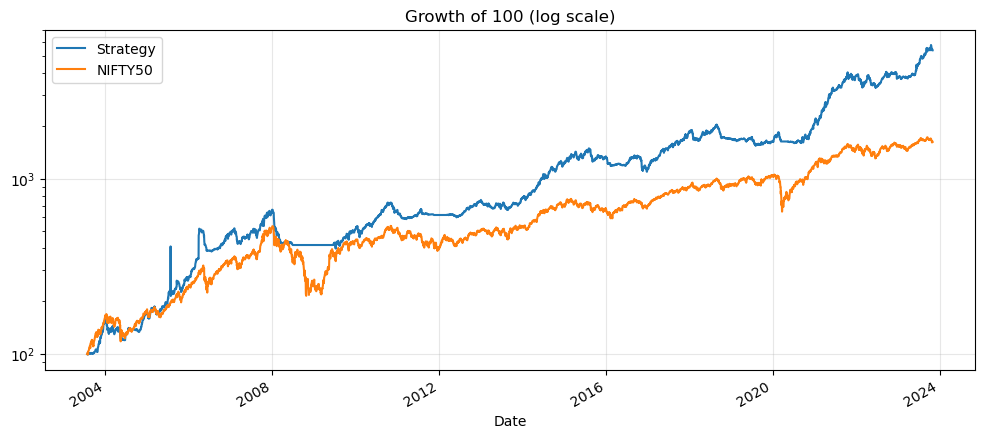

In [24]:
"""
TREND + PULLBACK STRATEGY  (sector > 55, other stocks included)

  1. Sector index monthly RSI > 55
       - stocks with a sector index use their own sector index
       - 'other' stocks (no sector index) use NIFTY50 monthly RSI > 55
  2. Stock monthly RSI > 60 and weekly RSI > 60            (trend filter)
  3. Signal: daily RSI crosses back above 50                (pullback ends)
  4. Buy at NEXT day's open
  5. Stop = entry - ATR_MULT x ATR(14), trailing (highest close - ATR_MULT x ATR), only moves up
  6. size_pct of equity per trade, whole shares, max_pos open positions
  7. Cost per side is a setting (default 0)

Needs in the notebook: stocks, sector_data, sector_plan, sector_bundle, other_stocks
(sector_data must contain "NIFTY50")
Already defined in earlier cells (not repeated here): np, pd, plt, RSI_LEN,
rsi(), period_rsi(), get_close(), monthly_rsi()
"""
ATR_LEN, RANK_LOOKBACK = 14, 60
START_CAPITAL = 100000        # % results are identical for any capital

FINAL = dict(
    sector_th=55, monthly_th=60, weekly_th=58, pullback_rsi=50,
    atr_mult=4.0,
    max_pos=15, size_pct=0.0667,
    sizing="pct",              # "pct" = fixed % of equity | "risk" = risk_pct of equity per trade
    risk_pct=0.01,
    include_other=True,
    cost=0.0,                  # per side, e.g. 0.001 = 0.1% on buy and on sell
    sector_fade_exit=False, max_hold=None,
    start=None, end=None,
)

# ============================ INDICATORS ============================
def atr(df, n=ATR_LEN):
    pc = df["Close"].shift(1)
    tr = pd.concat([df["High"] - df["Low"], (df["High"] - pc).abs(),
                    (df["Low"] - pc).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1 / n, min_periods=n, adjust=False).mean()

# ============================ PREPARATION (runs once) ============================
def prepare():
    sec_series, sec_last = {}, {}
    for sector, (idx_key, _) in sector_plan.items():
        sec_series[sector] = monthly_rsi(sector_data[idx_key])
        sec_last[sector] = sector_data[idx_key].index[-1]
    sec_series["Other"] = monthly_rsi(sector_data["NIFTY50"])
    sec_last["Other"] = sector_data["NIFTY50"].index[-1]

    mapping = {}
    for sector, b in sector_bundle.items():
        for t in b["stocks"]:
            mapping.setdefault(t, sector)
    for t in other_stocks:
        mapping.setdefault(t, "Other")

    pre = {}
    for name, df in stocks.items():
        if name not in mapping:
            continue
        close, sec = df["Close"], mapping[name]
        pre[name] = dict(
            sector=sec,
            ohlc=df[["Open", "High", "Low", "Close"]],
            atr=atr(df), mom=close.pct_change(RANK_LOOKBACK),
            d=rsi(close), w=period_rsi(close, "W"), m=period_rsi(close, "M"),
            sec_rsi=sec_series[sec].reindex(df.index, method="ffill"),
            sec_valid=pd.Series(df.index <= sec_last[sec], index=df.index),
        )
    return pre

PRE = prepare()
print(f"Prepared {len(PRE)} stocks "
      f"({sum(p['sector'] != 'Other' for p in PRE.values())} with sector index, "
      f"{sum(p['sector'] == 'Other' for p in PRE.values())} 'other')")

def make_frames(cfg):
    frames = {}
    for name, p in PRE.items():
        if p["sector"] == "Other" and not cfg["include_other"]:
            continue
        sec_ok = ((p["sec_rsi"] > cfg["sector_th"]) & p["sec_valid"]).fillna(False)
        trend = sec_ok & (p["m"] > cfg["monthly_th"]) & (p["w"] > cfg["weekly_th"])
        cross = (p["d"] > cfg["pullback_rsi"]) & (p["d"].shift(1) <= cfg["pullback_rsi"])
        f = p["ohlc"].copy()
        f["atr"], f["mom"] = p["atr"], p["mom"]
        f["sig"] = (trend & cross).fillna(False)
        f["sec_ok"] = sec_ok
        frames[name] = f
    return frames

# ============================ BACKTEST ============================
def run_backtest(cfg=None, verbose=False):
    cfg = {**FINAL, **(cfg or {})}
    frames = make_frames(cfg)

    # fast lookups: rows[name][date] -> dict, signals_by_date[date] -> [names]
    rows = {n: f.to_dict("index") for n, f in frames.items()}
    signals_by_date = {}
    for n, f in frames.items():
        for d in f.index[f["sig"].values]:
            signals_by_date.setdefault(d, []).append(n)

    dates = sorted(set().union(*[f.index for f in frames.values()]))
    if cfg["start"]:
        dates = [x for x in dates if x >= pd.Timestamp(cfg["start"])]
    if cfg["end"]:
        dates = [x for x in dates if x <= pd.Timestamp(cfg["end"])]

    equity = START_CAPITAL
    open_pos, pending, trades, mtm, n_open = {}, [], [], [], []
    n_signals, cost, mult = 0, cfg["cost"], cfg["atr_mult"]

    def close_trade(name, pos, date, px, reason):
        nonlocal equity
        fees = cost * pos["qty"] * (pos["entry"] + px)          # buy side + sell side
        pnl = pos["qty"] * (px - pos["entry"]) - fees
        equity += pnl
        trades.append({
            "Stock": name, "Sector": PRE[name]["sector"],
            "Signal_Date": pos["signal_date"], "Entry_Date": pos["entry_date"],
            "Entry": pos["entry"], "Qty": pos["qty"], "Init_SL": pos["init_sl"],
            "Exit_Date": date, "Exit": px, "Reason": reason,
            "Ret_%": (px / pos["entry"] - 1) * 100,
            "R": (px - pos["entry"]) / (pos["entry"] - pos["init_sl"]),
            "Fees": fees, "PnL": pnl,
            "Days": (date - pos["entry_date"]).days, "Equity": equity,
        })

    for d in dates:
        # 1) manage open positions
        for name in list(open_pos):
            row = rows[name].get(d)
            if row is None:
                continue
            pos = open_pos[name]
            if row["Open"] <= pos["stop"]:
                close_trade(name, pos, d, row["Open"], "Stop(gap)"); del open_pos[name]; continue
            if row["Low"] <= pos["stop"]:
                close_trade(name, pos, d, pos["stop"], "Stop"); del open_pos[name]; continue
            pos["hi"] = max(pos["hi"], row["Close"])
            if pd.notna(row["atr"]):
                pos["stop"] = max(pos["stop"], pos["hi"] - mult * row["atr"])
            if cfg["sector_fade_exit"] and not row["sec_ok"]:
                close_trade(name, pos, d, row["Close"], "SectorFade"); del open_pos[name]
            elif cfg["max_hold"] and (d - pos["entry_date"]).days >= cfg["max_hold"]:
                close_trade(name, pos, d, row["Close"], "TimeStop"); del open_pos[name]

        # 2) fill yesterday's signals at today's open (strongest momentum first)
        for mom, name, sig_atr, sig_date in sorted(pending, reverse=True):
            if len(open_pos) >= cfg["max_pos"]:
                break
            row = rows[name].get(d)
            if name in open_pos or row is None:
                continue
            entry = row["Open"]
            stop = entry - mult * sig_atr
            if stop <= 0 or entry <= stop:
                continue
            qty = int((equity * cfg["size_pct"]) // entry)
            if cfg["sizing"] == "risk":
                qty = min(int((equity * cfg["risk_pct"]) // (entry - stop)), qty)
            cash = equity - sum(p["qty"] * p["entry"] for p in open_pos.values())
            qty = min(qty, int(cash // entry))                  # never exceed available cash
            if qty < 1:
                continue
            pos = {"entry": entry, "qty": qty, "stop": stop, "init_sl": stop,
                   "hi": entry, "entry_date": d, "signal_date": sig_date}
            if row["Low"] <= stop:                              # stopped out on entry day
                close_trade(name, pos, d, stop, "Stop"); continue
            pos["hi"] = max(entry, row["Close"])
            if pd.notna(row["atr"]):
                pos["stop"] = max(stop, pos["hi"] - mult * row["atr"])
            open_pos[name] = pos
        pending = []

        # 3) new signals at today's close -> buy tomorrow's open
        for name in signals_by_date.get(d, []):
            n_signals += 1
            if name not in open_pos:
                r = rows[name][d]
                if pd.notna(r["mom"]) and pd.notna(r["atr"]) and r["atr"] > 0:
                    pending.append((r["mom"], name, r["atr"], d))

        # 4) mark-to-market
        unreal = sum(p["qty"] * (rows[n][d]["Close"] - p["entry"])
                     for n, p in open_pos.items() if d in rows[n])
        mtm.append((d, equity + unreal))
        n_open.append(len(open_pos))

    # close what is still open AT THE CUTOFF DATE (no look-ahead past `end`)
    for name, pos in list(open_pos.items()):
        f_cut = frames[name].loc[:dates[-1]]
        close_trade(name, pos, f_cut.index[-1], f_cut["Close"].iloc[-1], "OpenAtEnd")

    trades = pd.DataFrame(trades)
    mtm = pd.Series(dict(mtm))
    if trades.empty:
        return dict(Trades=0), trades, mtm

    t = trades.sort_values("Exit_Date").reset_index(drop=True)
    wins, losses = t[t["PnL"] > 0], t[t["PnL"] <= 0]
    first = t["Entry_Date"].min()
    years = max((mtm.index[-1] - first).days / 365.25, 1e-9)
    live = mtm[mtm.index >= first]
    n_open_s = pd.Series(n_open, index=mtm.index)
    stats = dict(
        Trades=len(t), Signals=n_signals,
        Trades_per_yr=round(len(t) / years, 1),
        WinRate=round(len(wins) / len(t) * 100, 1),
        AvgR=round(t["R"].mean(), 2),
        PF=round(wins["PnL"].sum() / abs(losses["PnL"].sum()), 2)
           if len(losses) and losses["PnL"].sum() else np.nan,
        Return_pct=round((equity / START_CAPITAL - 1) * 100, 1),
        CAGR_pct=round(((equity / START_CAPITAL) ** (1 / years) - 1) * 100, 1),
        MaxDD_pct=round((live / live.cummax() - 1).min() * 100, 1),
        Avg_open=round(n_open_s[n_open_s.index >= first].mean(), 2),
        AvgHold_d=round(t["Days"].mean(), 1),
    )
    if verbose:
        print("\n================ RESULTS ================")
        for k, v in stats.items():
            print(f"{k:>14}: {v}")
        print(f"{'Avg win':>14}: {wins['PnL'].mean():,.0f} | Avg loss: {losses['PnL'].mean():,.0f}")
        print("\nExit reasons:\n", t["Reason"].value_counts().to_string())
        print("\nBy sector:\n", t.groupby("Sector").agg(
            Trades=("PnL", "count"), WinRate=("PnL", lambda s: (s > 0).mean() * 100),
            PnL=("PnL", "sum")).round(1).sort_values("PnL", ascending=False).to_string())
        print("\nBy year (P&L):\n",
              t.groupby(t["Exit_Date"].dt.year)["PnL"].agg(["count", "sum"]).round(0).to_string())
    return stats, t, mtm

# ============================ RUN THE STRATEGY ============================
stats, trades, equity = run_backtest(FINAL, verbose=True)

# ---- benchmark: NIFTY50 buy-and-hold over the same dates ----
eq = equity[equity.index >= trades["Entry_Date"].min()]
nifty_close = get_close(sector_data["NIFTY50"]).dropna()
nf = nifty_close[(nifty_close.index >= eq.index[0]) & (nifty_close.index <= eq.index[-1])]
yrs = (nf.index[-1] - nf.index[0]).days / 365.25
n_cagr = ((nf.iloc[-1] / nf.iloc[0]) ** (1 / yrs) - 1) * 100
n_dd = (nf / nf.cummax() - 1).min() * 100

print("\n================ VS NIFTY50 BUY & HOLD ================")
print(f"Period: {eq.index[0].date()} to {eq.index[-1].date()}  ({yrs:.1f} years)")
print(f"Strategy : CAGR {stats['CAGR_pct']:.1f}% | Max DD {stats['MaxDD_pct']:.1f}%")
print(f"NIFTY50  : CAGR {n_cagr:.1f}% | Max DD {n_dd:.1f}%  (price index, no dividends)")

def yearly_returns(s):
    ye = s.groupby(s.index.year).last()
    prev = ye.shift(1)
    prev.iloc[0] = s.iloc[0]
    return (ye / prev - 1) * 100

yr = pd.DataFrame({"Strategy_%": yearly_returns(eq), "NIFTY50_%": yearly_returns(nf)}).round(1)
yr["Diff"] = (yr["Strategy_%"] - yr["NIFTY50_%"]).round(1)
print("\nYear-by-year return:")
print(yr.to_string())
print(f"\nYears strategy beat NIFTY50: {(yr['Diff'] > 0).sum()} of {len(yr)}")

fig, ax = plt.subplots(figsize=(12, 5))
(eq / eq.iloc[0] * 100).plot(ax=ax, label="Strategy")
(nf / nf.iloc[0] * 100).plot(ax=ax, label="NIFTY50")
ax.set_yscale("log"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Growth of 100 (log scale)")
plt.show()

# trades.to_csv("sector55_other_trades.csv", index=False)

In [25]:
# Positive vs negative trades
total = len(trades)
pos = int((trades["PnL"] > 0).sum())     # made a profit
neg = int((trades["PnL"] <= 0).sum())    # lost money (or broke even)

print(f"Total trades : {total}")
print(f"Positive     : {pos}  ({pos / total * 100:.1f}%)")
print(f"Negative     : {neg}  ({neg / total * 100:.1f}%)")

Total trades : 1069
Positive     : 508  (47.5%)
Negative     : 561  (52.5%)


In [26]:
r = trades["Ret_%"]
buckets = pd.cut(r, bins=[-float("inf"), 0, 1, 2, 3, float("inf")], right=False,
                 labels=["Below 0%", "0% to 1%", "1% to 2%", "2% to 3%", "3% and above"])
out = buckets.value_counts().sort_index().to_frame("Trades")
out["Share_%"] = (out["Trades"] / len(r) * 100).round(1)
print(out.to_string())
print(f"\nTotal trades: {len(r)}")

              Trades  Share_%
Below 0%         561     52.5
0% to 1%          24      2.2
1% to 2%          23      2.2
2% to 3%          28      2.6
3% and above     433     40.5

Total trades: 1069


Period: 2003-07-29 to 2023-11-01 (20.3 yrs) | RF = 6.0% | MAR = 6.0%

=========== STRATEGY vs NIFTY50 ===========
                        Strategy  NIFTY50
Total Return %           5271.25  1516.44
CAGR %                     21.73    14.72
Annual Volatility %        17.46    22.04
Downside Deviation %       11.02    15.67
Sharpe Ratio                0.90     0.48
Sortino Ratio               1.43     0.68
Calmar Ratio                0.54     0.25
Max Drawdown %            -39.94   -59.86
Max DD Duration (days)    978.00  1088.00
Best Day %                 34.41    17.74
Worst Day %                -7.02   -12.98
Positive Days %            52.70    54.20
Best Month %               50.07    28.07
Worst Month %             -21.35   -26.41
Positive Months %          60.41    60.00
Daily VaR 95% (%)           1.47     2.04
Daily CVaR 95% (%)          2.41     3.29
Skewness                    5.88    -0.18
Kurtosis (excess)         193.96    12.92

=========== STRATEGY RELATIVE TO NIFTY50 ====

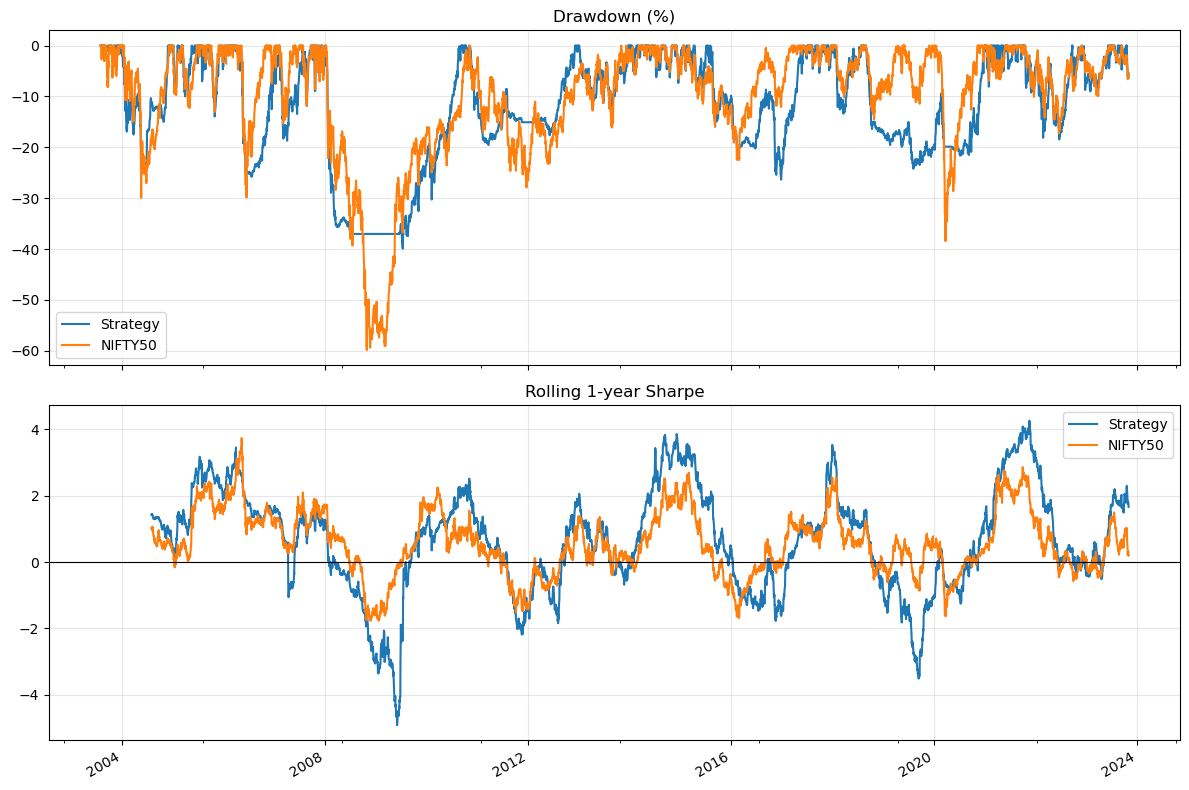

In [27]:
# ============================ STRATEGY vs NIFTY50: RISK / RETURN METRICS ============================
# Needs from earlier cells: equity, trades, sector_data, get_close, plt, np, pd
TRADING_DAYS = 252
RF_ANNUAL    = 0.06      # risk-free rate used for Sharpe / alpha / Treynor
MAR_ANNUAL   = 0.06      # minimum acceptable return (target) used for Sortino
CONF         = 0.95      # confidence level for VaR / CVaR

# ---------- 1) Build aligned level series (starts at the strategy's first trade) ----------
strat_lvl = equity[equity.index >= trades["Entry_Date"].min()].sort_index()
nifty_lvl = get_close(sector_data["NIFTY50"]).dropna().sort_index()

common    = strat_lvl.index.intersection(nifty_lvl.index)
strat_lvl = strat_lvl.loc[common]
nifty_lvl = nifty_lvl.loc[common]

strat_ret = strat_lvl.pct_change().dropna()          # returns computed AFTER alignment,
nifty_ret = nifty_lvl.pct_change().dropna()          # so both cover exactly the same days

# ---------- 2) Metric functions ----------
def daily_rate(annual):
    return (1 + annual) ** (1 / TRADING_DAYS) - 1

def cagr(lvl):
    yrs = (lvl.index[-1] - lvl.index[0]).days / 365.25
    return (lvl.iloc[-1] / lvl.iloc[0]) ** (1 / yrs) - 1

def sharpe(r, rf=RF_ANNUAL):
    ex = r - daily_rate(rf)
    return np.sqrt(TRADING_DAYS) * ex.mean() / ex.std(ddof=1)

def downside_dev(r, mar=MAR_ANNUAL):                 # annualised
    d = np.minimum(r - daily_rate(mar), 0)
    return np.sqrt((d ** 2).mean()) * np.sqrt(TRADING_DAYS)

def sortino(r, mar=MAR_ANNUAL):
    dd = downside_dev(r, mar)
    return (r.mean() - daily_rate(mar)) * TRADING_DAYS / dd if dd > 0 else np.nan

def drawdown(lvl):
    return lvl / lvl.cummax() - 1

def max_dd_days(lvl):                                # longest time spent below a previous peak
    peak, peak_date, longest = lvl.iloc[0], lvl.index[0], 0
    for d, v in lvl.items():
        if v >= peak:
            longest = max(longest, (d - peak_date).days)
            peak, peak_date = v, d
    return max(longest, (lvl.index[-1] - peak_date).days)

def var_cvar(r, conf=CONF):
    q = r.quantile(1 - conf)
    return -q, -r[r <= q].mean()                     # reported as positive losses

def monthly_returns(lvl):
    me   = lvl.groupby(lvl.index.to_period("M")).last()
    prev = me.shift(1)
    prev.iloc[0] = lvl.iloc[0]
    return me / prev - 1

def beta_alpha(r, b, rf=RF_ANNUAL):
    ex_r, ex_b = r - daily_rate(rf), b - daily_rate(rf)
    beta  = np.cov(ex_r, ex_b, ddof=1)[0, 1] / ex_b.var(ddof=1)
    alpha = (ex_r.mean() - beta * ex_b.mean()) * TRADING_DAYS     # annualised Jensen's alpha
    return beta, alpha

def capture(r, b):
    up, dn = b > 0, b < 0
    return r[up].mean() / b[up].mean(), r[dn].mean() / b[dn].mean()

# ---------- 3) Metrics table ----------
def core_metrics(lvl, r):
    mdd = drawdown(lvl).min()
    c   = cagr(lvl)
    mr  = monthly_returns(lvl)
    v95, cv95 = var_cvar(r)
    return {
        "Total Return %":            (lvl.iloc[-1] / lvl.iloc[0] - 1) * 100,
        "CAGR %":                    c * 100,
        "Annual Volatility %":       r.std(ddof=1) * np.sqrt(TRADING_DAYS) * 100,
        "Downside Deviation %":      downside_dev(r) * 100,
        "Sharpe Ratio":              sharpe(r),
        "Sortino Ratio":             sortino(r),
        "Calmar Ratio":              c / abs(mdd),
        "Max Drawdown %":            mdd * 100,
        "Max DD Duration (days)":    max_dd_days(lvl),
        "Best Day %":                r.max() * 100,
        "Worst Day %":               r.min() * 100,
        "Positive Days %":           (r > 0).mean() * 100,
        "Best Month %":              mr.max() * 100,
        "Worst Month %":             mr.min() * 100,
        "Positive Months %":         (mr > 0).mean() * 100,
        f"Daily VaR {int(CONF*100)}% (%)":   v95 * 100,
        f"Daily CVaR {int(CONF*100)}% (%)":  cv95 * 100,
        "Skewness":                  r.skew(),
        "Kurtosis (excess)":         r.kurt(),
    }

res = pd.DataFrame({"Strategy": core_metrics(strat_lvl, strat_ret),
                    "NIFTY50":  core_metrics(nifty_lvl, nifty_ret)})

# ---------- 4) Strategy relative to NIFTY50 ----------
beta, alpha = beta_alpha(strat_ret, nifty_ret)
active      = strat_ret - nifty_ret
te          = active.std(ddof=1) * np.sqrt(TRADING_DAYS)
up_cap, dn_cap = capture(strat_ret, nifty_ret)

rel = pd.Series({
    "Beta":                    beta,
    "Alpha % (annual)":        alpha * 100,
    "Correlation":             strat_ret.corr(nifty_ret),
    "Tracking Error %":        te * 100,
    "Information Ratio":       (cagr(strat_lvl) - cagr(nifty_lvl)) / te,
    "Treynor Ratio":           (cagr(strat_lvl) - RF_ANNUAL) / beta,
    "Up Capture":              up_cap,
    "Down Capture":            dn_cap,
    "Excess CAGR % vs NIFTY":  (cagr(strat_lvl) - cagr(nifty_lvl)) * 100,
})

print(f"Period: {strat_lvl.index[0].date()} to {strat_lvl.index[-1].date()} "
      f"({(strat_lvl.index[-1] - strat_lvl.index[0]).days / 365.25:.1f} yrs) | "
      f"RF = {RF_ANNUAL:.1%} | MAR = {MAR_ANNUAL:.1%}\n")
print("=========== STRATEGY vs NIFTY50 ===========")
print(res.round(2).to_string())
print("\n=========== STRATEGY RELATIVE TO NIFTY50 ===========")
print(rel.round(2).to_string())

# ---------- 5) Charts: drawdown + rolling 1-year Sharpe ----------
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

(drawdown(strat_lvl) * 100).plot(ax=ax[0], label="Strategy")
(drawdown(nifty_lvl) * 100).plot(ax=ax[0], label="NIFTY50")
ax[0].set_title("Drawdown (%)"); ax[0].legend(); ax[0].grid(alpha=0.3)

def rolling_sharpe(r, win=TRADING_DAYS):
    ex = r - daily_rate(RF_ANNUAL)
    return np.sqrt(TRADING_DAYS) * ex.rolling(win).mean() / ex.rolling(win).std(ddof=1)

rolling_sharpe(strat_ret).plot(ax=ax[1], label="Strategy")
rolling_sharpe(nifty_ret).plot(ax=ax[1], label="NIFTY50")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Rolling 1-year Sharpe"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

,Stock,Sector,Signal_Date,Entry_Date,Exit_Date,Days,Entry,Exit,Qty,Ret_%,R,PnL,Reason
Trade_No,,,,,,,,,,,,,
1,BHEL.NS,Other,2003-07-28,2003-07-29,2003-11-26,120,14.16,16.74,471,18.22,1.09,1214.87,Stop(gap)
2,LINDEINDIA.NS,Other,2003-08-04,2003-08-05,2003-09-15,41,38.31,32.74,174,-14.53,-0.58,-968.77,Stop(gap)
3,SHREECEM.NS,Other,2003-08-26,2003-08-27,2003-10-24,58,83.01,72.86,80,-12.22,-0.42,-811.68,Stop
4,SIEMENS.NS,Other,2003-09-19,2003-09-22,2004-01-23,123,36.02,76.60,183,112.67,7.83,7426.85,Stop
5,VOLTAS.NS,Other,2003-09-30,2003-10-01,2004-01-21,112,0.44,0.57,14880,29.39,1.84,1941.30,Stop
6,PIDILITIND.NS,Other,2003-10-06,2003-10-07,2003-10-22,15,5.85,5.61,1129,-4.06,-0.33,-268.36,Stop
7,ASIANPAINT.NS,Other,2003-10-07,2003-10-08,2003-10-22,14,23.63,22.54,279,-4.61,-0.55,-303.66,Stop
8,CGPOWER.NS,Other,2003-10-15,2003-10-16,2004-01-09,85,0.04,0.11,160567,162.57,8.66,10738.14,Stop
9,AMBUJACEM.NS,Other,2003-10-16,2003-10-17,2004-01-21,96,20.90,24.31,316,16.29,1.00,1075.86,Stop




In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------- 1) Full trade list with start and end dates ----------
cols = ["Stock", "Sector", "Signal_Date", "Entry_Date", "Exit_Date", "Days",
        "Entry", "Exit", "Qty", "Ret_%", "R", "PnL", "Reason"]

trade_log = (trades[cols]
             .sort_values(["Entry_Date", "Stock"])
             .reset_index(drop=True))
trade_log.index += 1                                   # trade numbers start at 1
trade_log.index.name = "Trade_No"

for c in ["Signal_Date", "Entry_Date", "Exit_Date"]:   # show plain dates, no time part
    trade_log[c] = pd.to_datetime(trade_log[c]).dt.strftime("%Y-%m-%d")

trade_log[["Entry", "Exit", "Ret_%", "R", "PnL"]] = trade_log[["Entry", "Exit", "Ret_%", "R", "PnL"]].round(2)

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 250):
    display(trade_log)                                 # use print(trade_log.to_string()) outside Jupyter

# trade_log.to_csv("all_trades_with_dates.csv")        # uncomment to save

# ---------- 2) Handy filters ----------
# One stock:       trade_log[trade_log["Stock"] == "RELIANCE.NS"]
# One year:        trade_log[trade_log["Entry_Date"].str.startswith("2023")]
# Still open:      trade_log[trade_log["Reason"] == "OpenAtEnd"]
# Losing trades:   trade_log[trade_log["PnL"] <= 0]

# ---------- 3) Timeline chart: one bar per trade (green = profit, red = loss) ----------
t = trades.sort_values("Entry_Date").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(14, max(6, 0.12 * len(t))))
for i, r in enumerate(t.itertuples()):
    start = mdates.date2num(r.Entry_Date)
    width = max(mdates.date2num(r.Exit_Date) - start, 1)      # at least 1 day wide so it is visible
    ax.broken_barh([(start, width)], (i - 0.4, 0.8),
                   facecolors="tab:green" if r.PnL > 0 else "tab:red")

ax.set_ylim(len(t), -1)                                       # first trade at the top
ax.set_yticks([])
ax.set_ylabel(f"{len(t)} trades (oldest at top)")
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="x", alpha=0.3)
ax.set_title("Trade timeline: entry date to exit date")
plt.tight_layout()
plt.show()